# CellPLM Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 03.12.2024
- Date of Last Modification: 12.01.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Clone CellPLM from GitHub into ```<root>/analysis/benchmarking```: ```https://github.com/OmicsML/CellPLM.git```.
- Install the cellplm conda environment ```../../envs/cellplm.yaml```, then run ```pip install -r requirements.txt``` inside the ```./CellPLM``` repository to run this notebook.
- If cu117 is not supported in your compute environment, update torch like ```pip install torch==2.4.0+cu124 --index-url https://download.pytorch.org/whl/cu124```
- Download the model checkpoint as described here https://github.com/OmicsML/CellPLM/tree/main and put it into the folder ```./CellPLM/ckpt```.
- This notebook follows the tutorial from https://github.com/OmicsML/CellPLM/blob/main/tutorials/cell_embedding.ipynb.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import os
import warnings

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from CellPLM.pipeline.cell_embedding import CellEmbeddingPipeline
from CellPLM.utils import set_seed
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/terra-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
cellplm_folder_path = '/nfs/team361/sb75/terra-reproducibility/analysis/benchmarking/CellPLM'

### 1.3 Define Config

In [5]:
PRETRAIN_VERSION = '20231027_85M'
DEVICE = 'cuda:0'
latent_neighborhood_cluster_key = 'predicted_niche'
latent_cell_cluster_key = 'predicted_cell_type'

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/CellPLM', exist_ok=True)

In [11]:
set_seed(42)

## 2. Zero-shot Niche Identification

In [12]:
# Init cell embedding pipeline
pipeline = CellEmbeddingPipeline(pretrain_prefix=PRETRAIN_VERSION, # Specify the pretrain checkpoint to load
                                 pretrain_directory=f'{cellplm_folder_path}/ckpt')
pipeline.model

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/CellPLM/pipeline/__init__.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  pretrained_model_dict 

OmicsFormer(
  (embedder): OmicsEmbeddingLayer(
    (act): ReLU()
    (norm0): GroupNorm(4, 1024, eps=1e-05, affine=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (extra_linear): Sequential(
      (0): Linear(in_features=1024, out_features=1024, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.2, inplace=False)
      (3): GroupNorm(4, 1024, eps=1e-05, affine=True)
    )
    (pe_enc): Sinusoidal2dPE(
      (pe_enc): Embedding(10000, 1024)
    )
    (feat_enc): OmicsEmbedder()
  )
  (mask_model): MaskBuilder()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x FlowformerLayer(
        (self_attn): Flow_Attention(
          (query_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (key_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (value_projection): Linear(in_features=1024, out_features=1024, bias=True)
          (out_projection): Linear(in_features=1024, out_features=1024, bias=True)
         

### 2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

This data is in the training data of CellPLM (no zero-shot).

#### 2.1.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
niche_key = 'niche'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

In [ ]:
print(adata.obs[niche_key].value_counts())

#### 2.1.2 Retrieve Embeddings

In [ ]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata,
           color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 2.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 0.32

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
niche_counts = (adata.obs[niche_key].value_counts() < 100)
invalid_niches = niche_counts[niche_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_neighborhood_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[niche_key].isin(invalid_niches)) & (~adata.obs[latent_neighborhood_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_neighborhood_cluster_key].unique().tolist())
print(filtered_df[latent_neighborhood_cluster_key].value_counts())

max_overlap_plot(filtered_df, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '0',
    '3',
    '1',
    '4',
    '2',
    '8',
    '10',
    '5',
    '6',
    '7',
    '11',
    '9']

In [ ]:
# Plot cellplm niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.1.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset params
dataset_name = 'chr78-11b_1p'
batches = ['CM007',
           'CM008',
           'CM009',
           'CM011',
           'CM013',
           'CM015',
           'CM016',
           'CM017',
           'CM018',
           'CM019',
           'CM020']
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

#### 2.2.1 Load Data

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.093 # conversion rate from Valentina

In [ ]:
# Combine regions
adata.obs[niche_key] = adata.obs[niche_key].apply(lambda x: x.replace('Urogenital Sinus', 'UrogenitalSinus'))

In [ ]:
print(adata.obs[niche_key].value_counts())

#### 2.2.2 Retrieve Embeddings

In [ ]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata,
           color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 2.2.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
latent_leiden_resolution = 1.2

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
niche_counts = (adata.obs[niche_key].value_counts() < 100)
invalid_niches = niche_counts[niche_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_neighborhood_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[niche_key].isin(invalid_niches)) & (~adata.obs[latent_neighborhood_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_neighborhood_cluster_key].unique().tolist())
print(filtered_df[latent_neighborhood_cluster_key].value_counts())

max_overlap_plot(filtered_df, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '17',
    '6',
    '16',
    '2',
    '4',
    '3',
    '1',
    '15',
    '12',
    '11',
    '10',
    '14',
    '8',
    '5',
    '0',
    '18',
    '9',
    '13',
    '7',]

In [ ]:
# Plot cellplm niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.2.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
spot_size = 20

#### 2.3.1 Load Data

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Xenium_Prime_Human_Skin_FFPE_outs.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs[niche_key].isna()]

In [ ]:
adata.obs[niche_key].value_counts()

#### 2.3.2 Retrieve Embeddings

In [ ]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata,
           color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 7)
latent_leiden_resolution = 0.168

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
niche_counts = (adata.obs[niche_key].value_counts() < 100)
invalid_niches = niche_counts[niche_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_neighborhood_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[niche_key].isin(invalid_niches)) & (~adata.obs[latent_neighborhood_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_neighborhood_cluster_key].unique().tolist())
print(filtered_df[latent_neighborhood_cluster_key].value_counts())

max_overlap_plot(filtered_df, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '5',
    '2',
    '3',
    '6',
    '4',
    '0',
    '1',]

In [ ]:
# Plot cellplm niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_cellplm_niches.svg'
sc.pl.spatial(adata,
              color=latent_neighborhood_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

#### 2.4.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
niche_key = 'niche_type'
batch_key = 'batch'
spot_sizes = [20] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

In [ ]:
print(adata.obs[niche_key].value_counts())

#### 2.4.2 Retrieve Embeddings

In [ ]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [ ]:
# Visualize UMAP
sc.pl.umap(adata,
           color=niche_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 2.4.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 11)
latent_leiden_resolution = 0.4

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_neighborhood_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_neighborhood_cluster_key].value_counts()

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
niche_counts = (adata.obs[niche_key].value_counts() < 100)
invalid_niches = niche_counts[niche_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_neighborhood_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[niche_key].isin(invalid_niches)) & (~adata.obs[latent_neighborhood_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_neighborhood_cluster_key].unique().tolist())
print(filtered_df[latent_neighborhood_cluster_key].value_counts())

max_overlap_plot(filtered_df, niche_key, latent_neighborhood_cluster_key)

In [ ]:
inferred_niches_ordered = [
    '1',
    '6',
    '0',
    '2',
    '9',
    '4',
    '5',
    '3',
    '7',
    '10',
    '8']

In [ ]:
# Plot cellplm niches
label2niche = {}
current_index = 0  # To keep track of the new indices

for niche in inferred_niches_ordered:
    if not isinstance(niche, str):
        if math.isnan(niche):
            continue # skip NaN values
    label2niche[str(current_index)] = niche
    current_index += 1

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_neighborhood_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_neighborhood_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 2.1.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_niches_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_niches_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[niche_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_niches': n_niches_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

## 3. Zero-shot Cell Type Identification

### 3.1 xhs1000-39b_1p (Xenium Human Eczema)

In [63]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
cell_type_key = 'new_annotation' # 'annotation_new7'
batch_key = 'batch'
spot_sizes = [20] * len(batches)

#### 3.5.1 Load Data

In [64]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1320700/3458664098.py:13: Imp

In [65]:
print(adata.obs[cell_type_key].value_counts())

KC1                               9861
KC4                               8301
F2: Universal                     6307
KC3                               4896
T                                 4430
KCinflamm                         3020
Sebocyte_GATA6hi_innersebocyte    2948
VE3                               2692
cDC2                              2601
Pericyte                          1937
Mac                               1590
Muscle                            1241
KC_melanocyte                     1019
Sweat gland channel outer          651
Schwann                            642
Sweat gland                        587
LE                                 347
F5: RAMP1                          328
Mast cell                          200
Pre-adipocyte PPARG+ANGPTL8         52
Plasma cell                          5
Name: new_annotation, dtype: int64


#### 3.5.2 Load Embeddings

In [66]:
# Load AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 3.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [78]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 19)
latent_leiden_resolution = 1.0

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [79]:
adata.obs[latent_cell_cluster_key].value_counts()

0     6230
1     6063
2     6031
3     4108
4     3845
5     3733
6     3494
7     2976
8     2903
9     2614
10    2446
11    1917
12    1703
13    1471
14    1231
15    1231
16    1052
17     392
18     164
19      51
Name: predicted_cell_type, dtype: int64

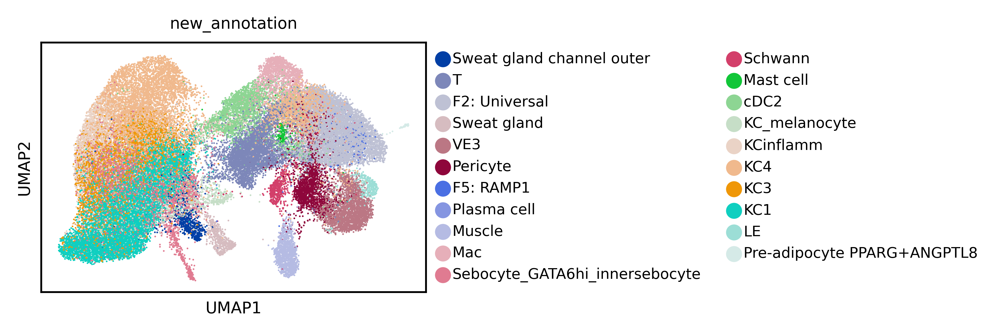

In [80]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [81]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered_cell_type.h5ad')

['5', '12', '3', '11', '10', '7', '18', '0', '16', '2', '15', '6', '1', '9', '8', '4', '13', '17', '14']
0     6230
1     6063
2     6031
3     4108
4     3845
5     3730
6     3494
7     2976
8     2903
9     2614
10    2446
11    1917
12    1703
13    1471
14    1231
15    1231
16    1048
17     392
18     164
19       0
Name: predicted_cell_type, dtype: int64
Optimal Mappings:
Sweat gland channel outer -> 4 (Overlap: 17)
T -> 3 (Overlap: 3676)
F2: Universal -> 2 (Overlap: 5172)
Sweat gland -> 14 (Overlap: 549)
VE3 -> 7 (Overlap: 2393)
Pericyte -> 11 (Overlap: 1524)
F5: RAMP1 -> 17 (Overlap: 0)
Muscle -> 15 (Overlap: 1197)
Mac -> 12 (Overlap: 1357)
Sebocyte_GATA6hi_innersebocyte -> 0 (Overlap: 1186)
Schwann -> 16 (Overlap: 496)
Mast cell -> 18 (Overlap: 155)
cDC2 -> 10 (Overlap: 1982)
KC_melanocyte -> 13 (Overlap: 22)
KCinflamm -> 8 (Overlap: 995)
KC4 -> 9 (Overlap: 2418)
KC3 -> 6 (Overlap: 1699)
KC1 -> 1 (Overlap: 4190)
LE -> 5 (Overlap: 7)

Total Maximum Overlap: 29035


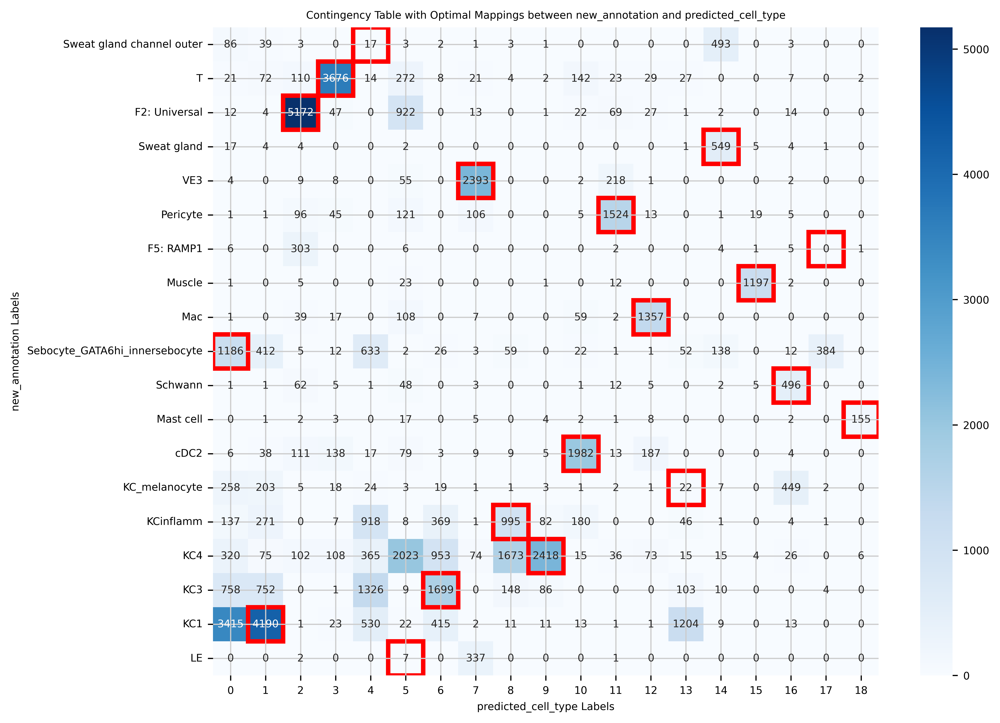

In [82]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [83]:
inferred_cell_types_ordered = [
    '4',
    '3',
    '2',
    '14',
    '7',
    '11',
    '17',
    '15',
    '12',
    '0',
    '16',
    '18',
    '10',
    '13',
    '8',
    '9',
    '6',
    '1',
    '5',
]

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


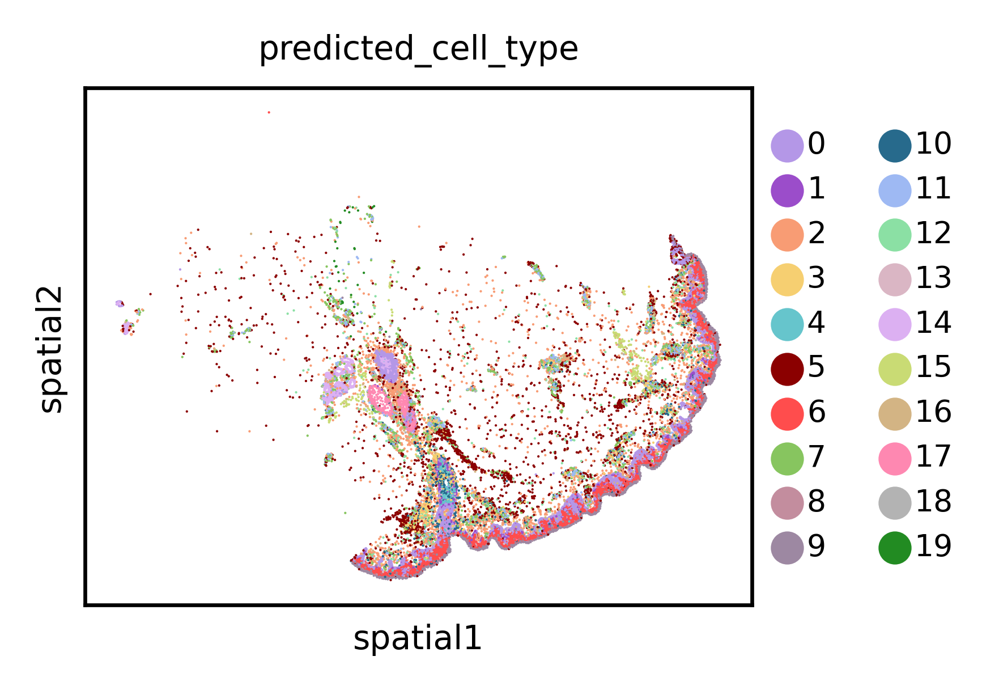

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


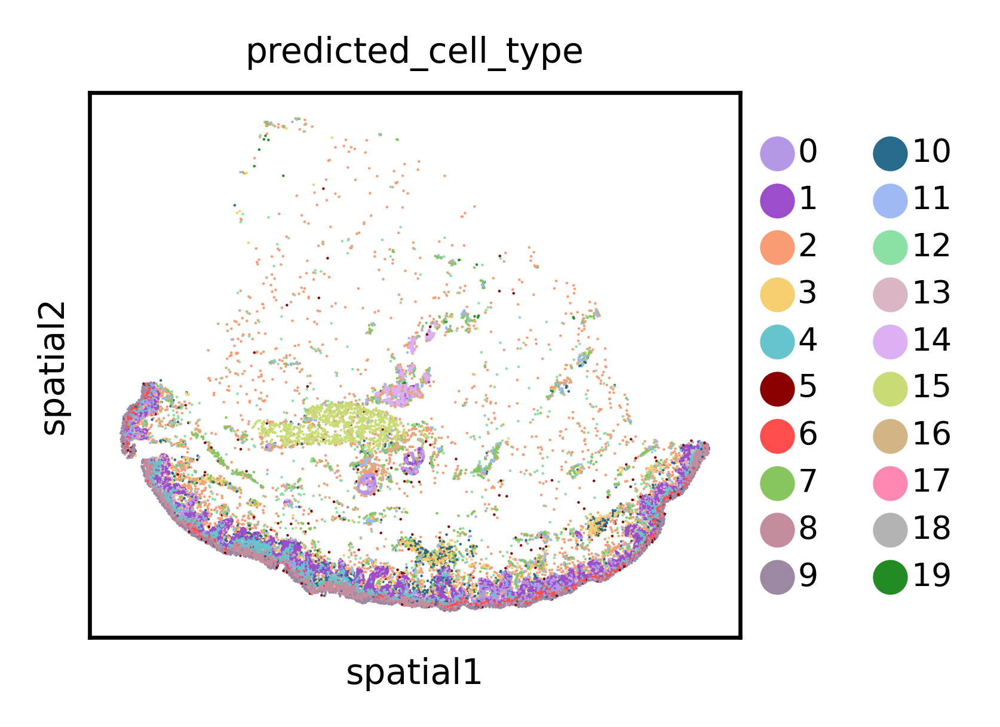

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


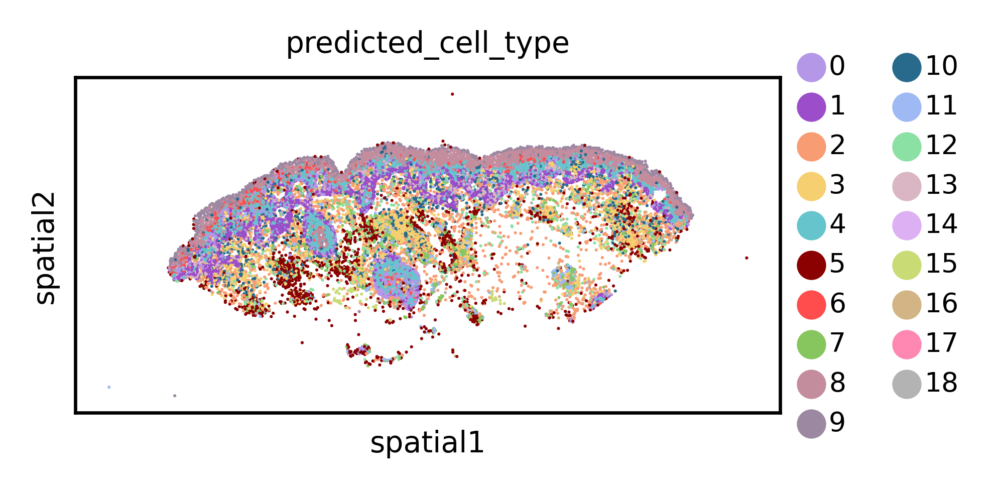

In [84]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [85]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5854629628966392.
ARI scores: 0.3968041356924011.


#### 3.1.4 Quantitative Performance

In [86]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5854629628966392, 0.5795322110312033, 0.5851308105060367, 0.590525828308558, 0.5829979651461771, 0.5838499506243702, 0.5776633567500297, 0.5819707775297376, 0.5862933232307574].
ARI scores: [0.3968041356924011, 0.38960263958943925, 0.3958755058532951, 0.4115198780907677, 0.3928201248221411, 0.396657569136136, 0.39133799842068223, 0.39367656036005605, 0.4022507321186206].


### 3.2 chl59-8b_1p (NanoString CosMx Human NSCLC)

In [48]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
cell_type_key = 'cell_type'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

#### 3.5.1 Load Data

In [49]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1320700/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_1320700/3458664098.py:13: Imp

In [50]:
print(adata.obs[cell_type_key].value_counts())

tumor          245918
fibroblast      59082
neutrophil      49628
myeloid         48953
NK/T cell       38465
plasmablast     26574
endothelial     24999
epithelial      17419
B-cell          16475
mast             6448
Name: cell_type, dtype: int64


#### 3.5.2 Load Embeddings

In [51]:
# Load AnnData
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 3.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [54]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 10)
latent_leiden_resolution = 0.2

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [55]:
adata.obs[latent_cell_cluster_key].value_counts()

0    110226
1     91147
2     76206
3     64028
4     55404
5     49289
6     32888
7     32671
8     17577
9      4525
Name: predicted_cell_type, dtype: int64

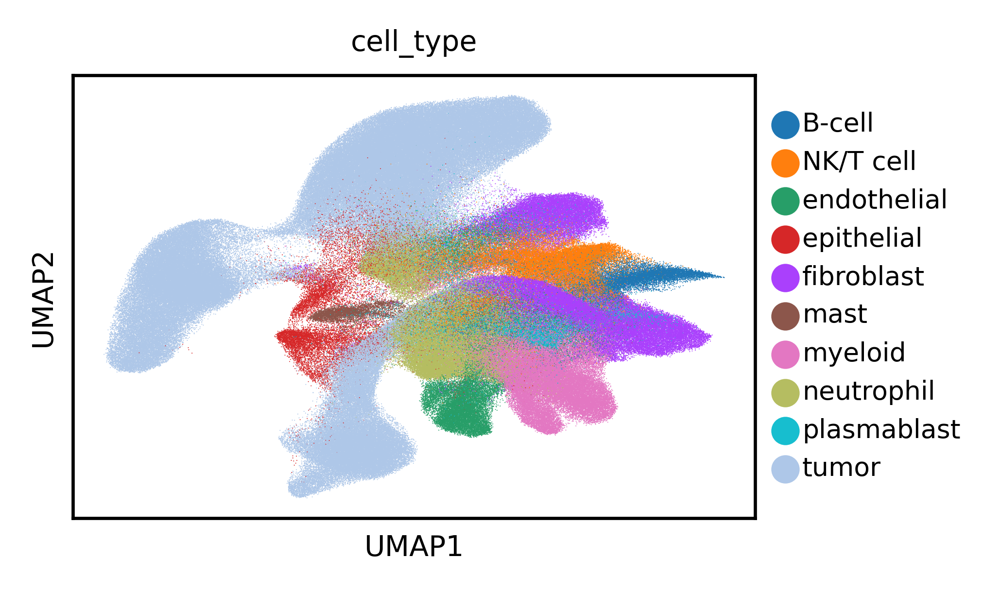

In [56]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [57]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered_cell_type.h5ad')

['3', '1', '8', '7', '6', '9', '4', '2', '5', '0']
0    110226
1     91147
2     76206
3     64028
4     55404
5     49289
6     32888
7     32671
8     17577
9      4525
Name: predicted_cell_type, dtype: int64
Optimal Mappings:
B-cell -> 3 (Overlap: 3)
NK/T cell -> 7 (Overlap: 18175)
endothelial -> 8 (Overlap: 16265)
epithelial -> 5 (Overlap: 5849)
fibroblast -> 1 (Overlap: 57514)
mast -> 9 (Overlap: 4202)
myeloid -> 6 (Overlap: 31667)
neutrophil -> 2 (Overlap: 34239)
plasmablast -> 4 (Overlap: 3797)
tumor -> 0 (Overlap: 109714)

Total Maximum Overlap: 281425


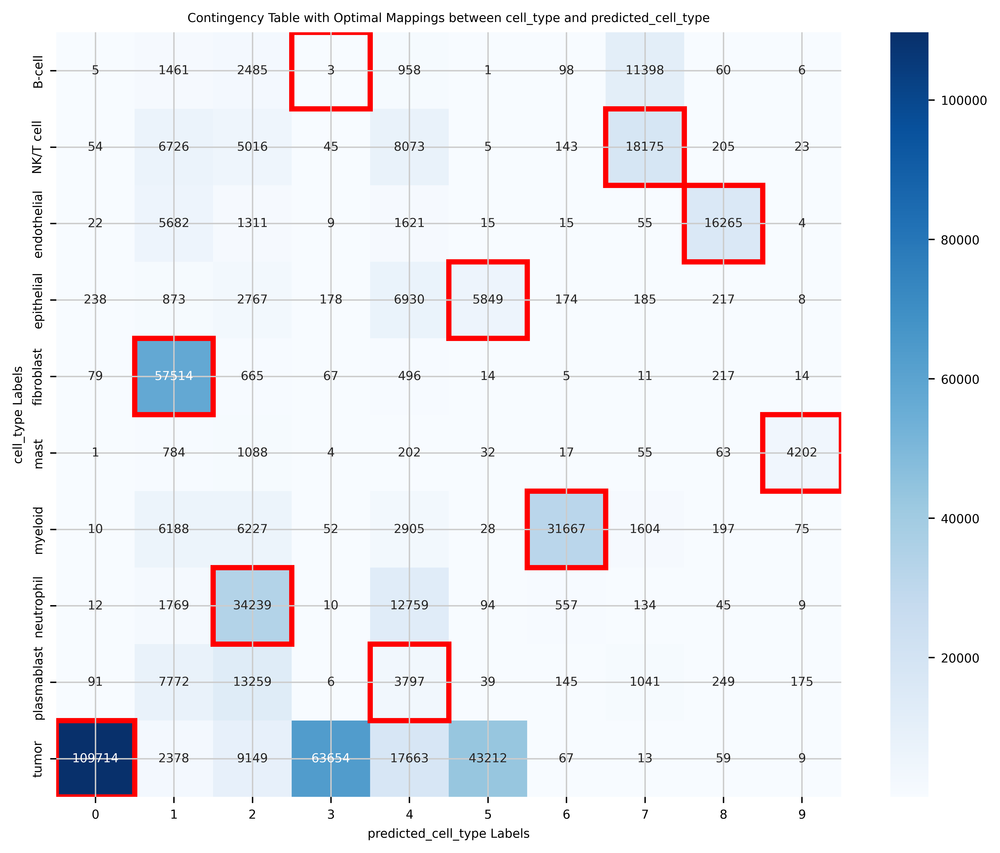

In [58]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [59]:
inferred_cell_types_ordered = [
    '3',
    '7',
    '8',
    '5',
    '1',
    '9',
    '6',
    '2',
    '4',
    '0',]

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


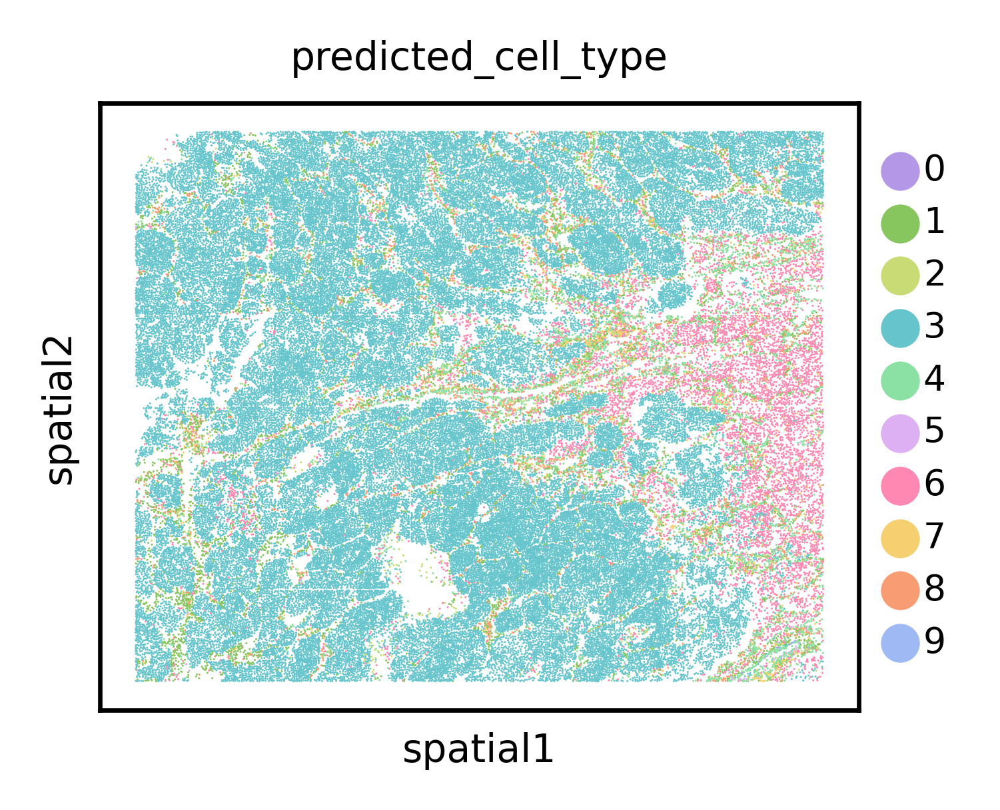

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


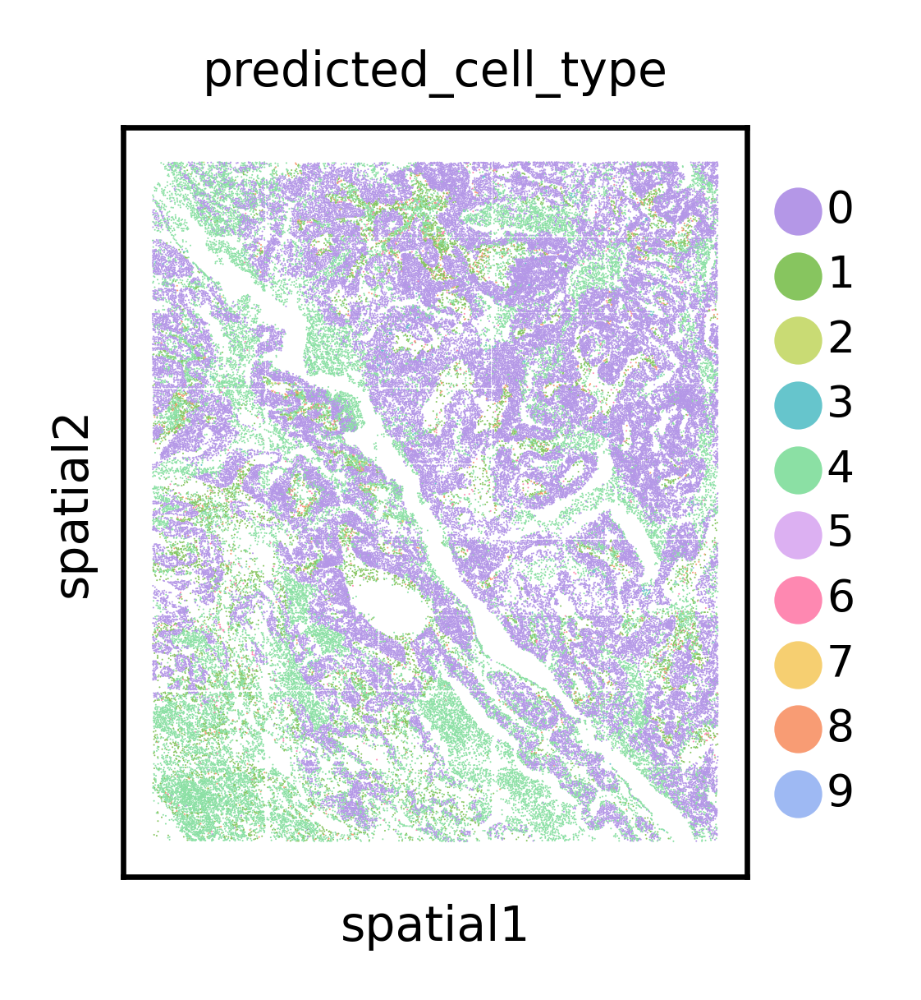

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


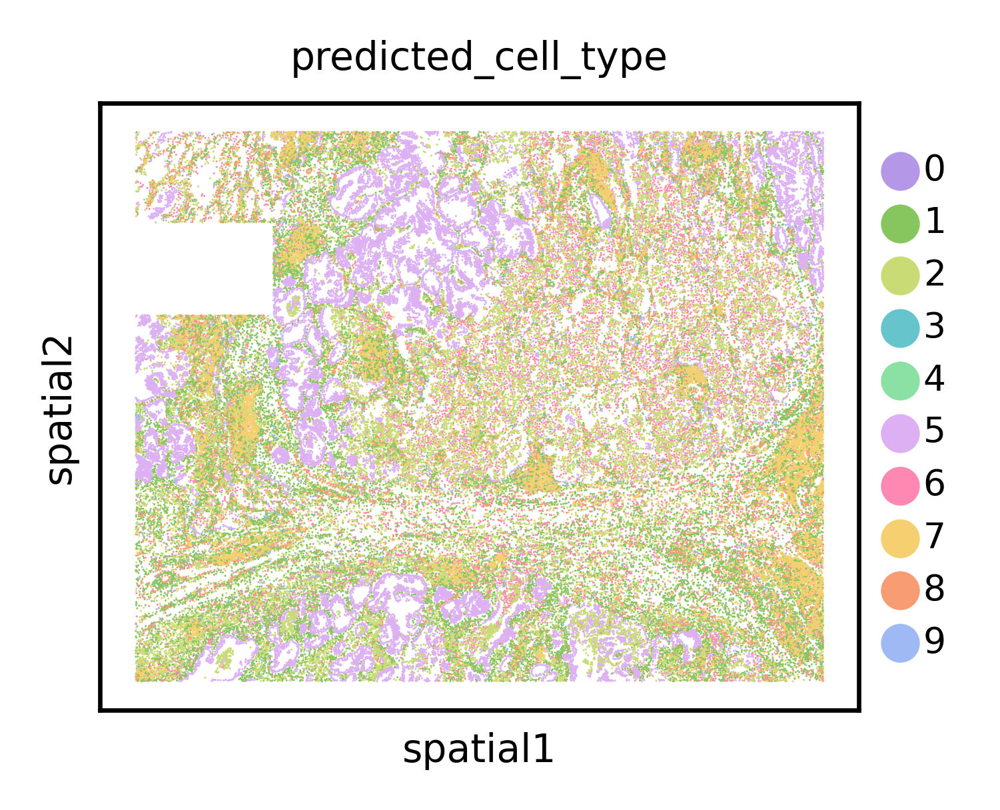

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


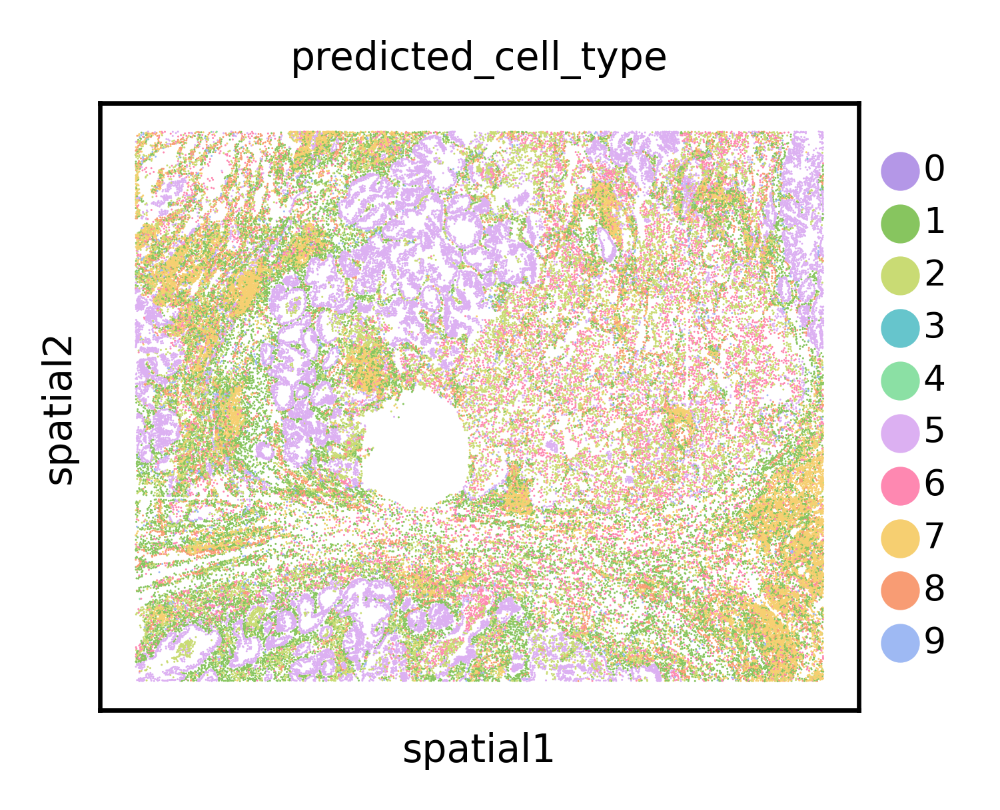

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


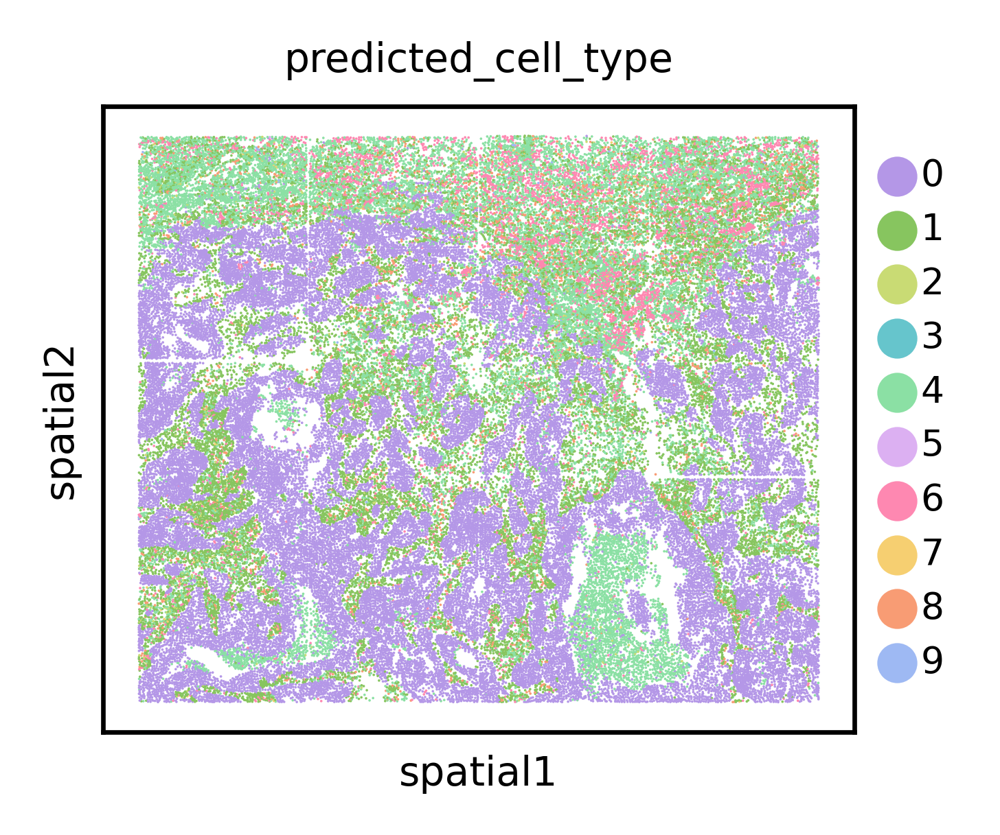

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


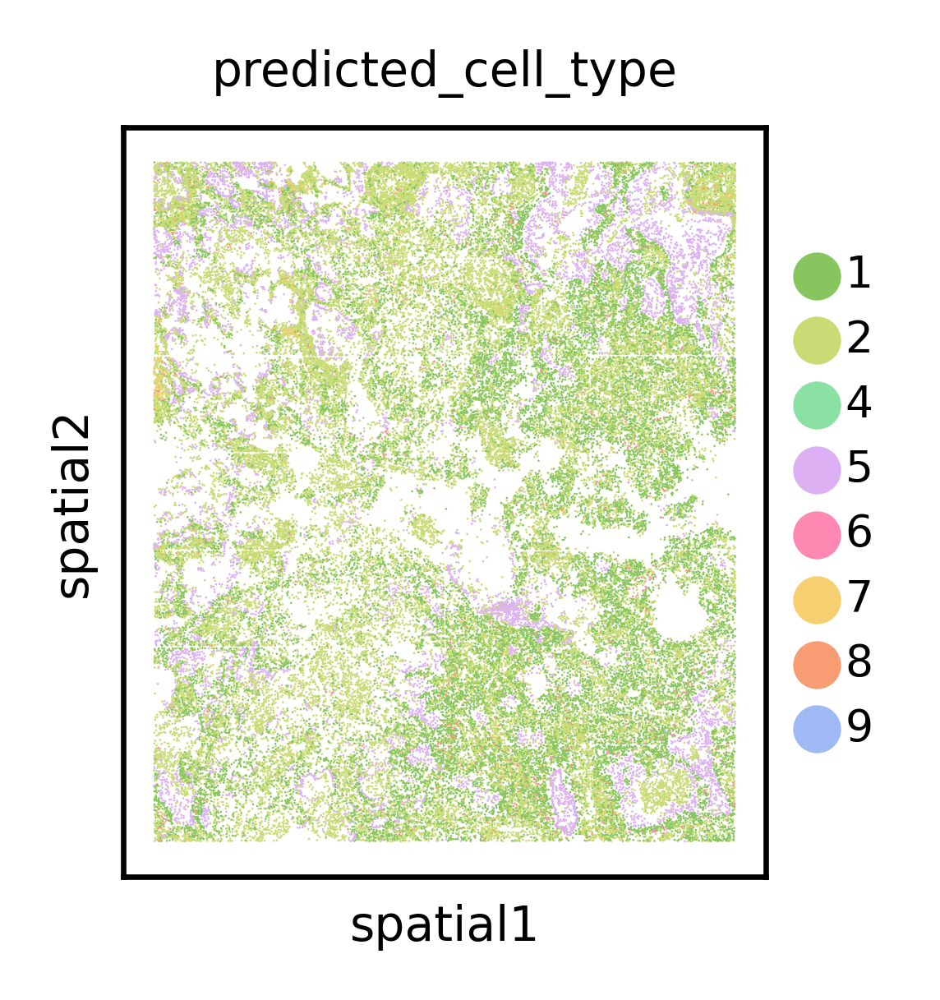

In [60]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [61]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5047128388625188.
ARI scores: 0.3432909947700234.


#### 3.1.4 Quantitative Performance

In [62]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5047128388625188, 0.4835928827778895, 0.4842191403565136, 0.49822573270700793, 0.5000407648572877, 0.46604895644843203, 0.49604679831615606, 0.5066055191134323, 0.5062817465874089].
ARI scores: [0.3432909947700234, 0.3133752764411394, 0.3146952119110823, 0.34127354507666474, 0.3424209118072783, 0.3154341124569526, 0.3407967101120206, 0.34127552930118144, 0.338112759980486].


### 3.3 xhk1007-CV1-41b_1p (Xenium Human Renal Cell Carcinoma)

#### 3.3.1 Load Data

In [ ]:
# Define dataset params
dataset_name = 'xhk1007-CV1-41b_1p'
batches = ['CV1-KID-0-FT-3', # 'batch1',
           'CV1-KID-0-FT-1' # 'batch14'
          ]
cell_type_key = 'level_1_cell_type'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
print(adata.obs[cell_type_key].value_counts())

#### 3.3.2 Retrieve Embeddings

In [ ]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

In [ ]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 3.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 5)
latent_leiden_resolution = 0.1675

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata.obs[latent_cell_cluster_key].value_counts()

In [ ]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [ ]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered.h5ad')

In [ ]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [ ]:
inferred_cell_types_ordered = [
    '1',
    '0',
    '4',
    '2',
    '3']

In [ ]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

#### 3.3.4 Quantitative Performance

In [ ]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

### 3.4 shp75-4b_1p (STARmap Human Placenta)

In [16]:
# Define dataset params
dataset_name = 'shp75-4b_1p'
batches = ['STARmap-ISS_sample_W11_',
           'STARmap-ISS_sample_W7_',
           'STARmap-ISS_sample_W8-2_',
           'STARmap-ISS_sample_W9_',
          ]
cell_type_key = 'leiden'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

OUT_PATH = f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}'
os.makedirs(OUT_PATH, exist_ok=True)

#### 3.5.1 Load Data

In [17]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/tmp/ipykernel_2004386/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2004386/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2004386/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/tmp/ipykernel_2004386/3458664098.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/software/cellgen/team361/sb75/envs/cellplm/

In [18]:
print(adata.obs[cell_type_key].value_counts())

0     1953
1     1926
2     1792
3     1682
4     1576
5     1418
6     1363
7     1228
8     1086
9      904
10     443
11     431
12     377
Name: leiden, dtype: int64


#### 3.5.2 Retrieve Embeddings

In [19]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
INFO:biothings.client:querying 1-946 ...


Automatically converting gene symbols to ensembl ids...


INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/CellPLM/utils/data.py:20: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at ../aten/src/ATen/SparseCsrTensorImpl.cpp:53.)
  return torch.sparse_csr_tensor(x.indptr, x.indices, x.data, (x.shape[0], x.shape[1])).to_sparse().float().coalesce()


After filtering, 893 genes remain.


In [20]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [21]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 3.1.3 Highlight Run (Matching Ground Truth Number of Niches)

In [32]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 13)
latent_leiden_resolution = 1.3

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [33]:
adata.obs[latent_cell_cluster_key].value_counts()

0     1807
1     1528
2     1527
3     1499
4     1440
5     1438
6     1428
7     1352
8     1303
9      989
10     936
11     705
12     227
Name: predicted_cell_type, dtype: int64

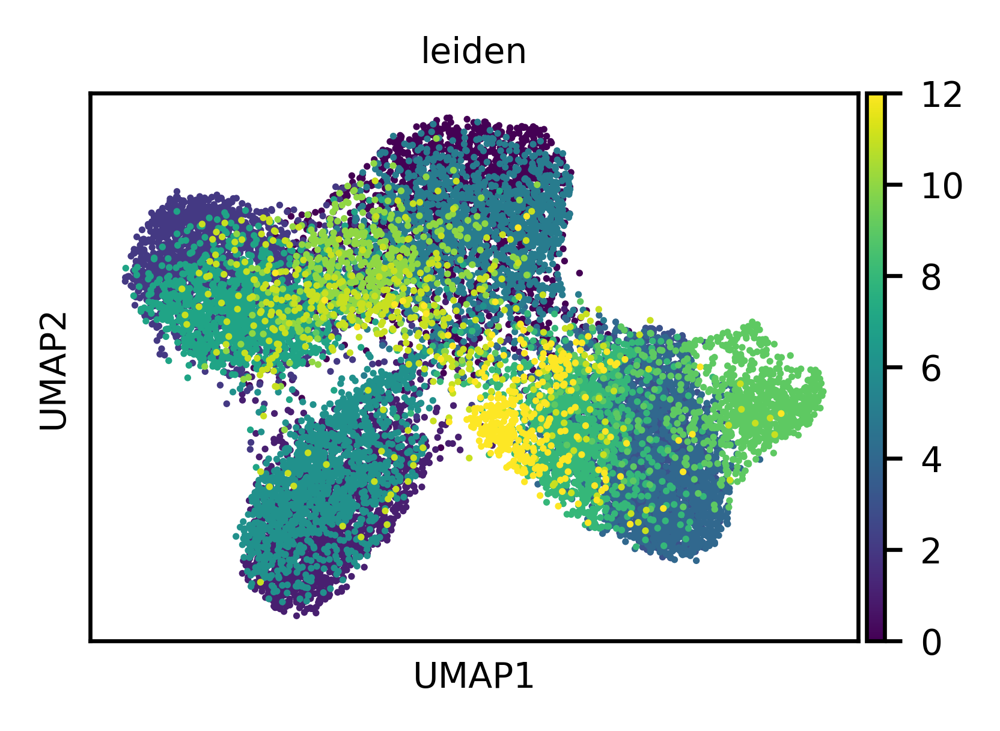

In [34]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [35]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered_cell_type.h5ad')

['5', '9', '3', '7', '6', '4', '10', '0', '11', '8', '2', '1', '12']
0     1807
1     1528
2     1527
3     1499
4     1440
5     1438
6     1428
7     1352
8     1303
9      989
10     936
11     705
12     227
Name: predicted_cell_type, dtype: int64
Optimal Mappings:
0 -> 11 (Overlap: 483)
1 -> 2 (Overlap: 1044)
2 -> 3 (Overlap: 1133)
3 -> 5 (Overlap: 686)
4 -> 0 (Overlap: 835)
5 -> 8 (Overlap: 625)
6 -> 1 (Overlap: 730)
7 -> 7 (Overlap: 717)
8 -> 4 (Overlap: 692)
9 -> 10 (Overlap: 774)
10 -> 9 (Overlap: 290)
11 -> 6 (Overlap: 150)
12 -> 12 (Overlap: 0)

Total Maximum Overlap: 8159


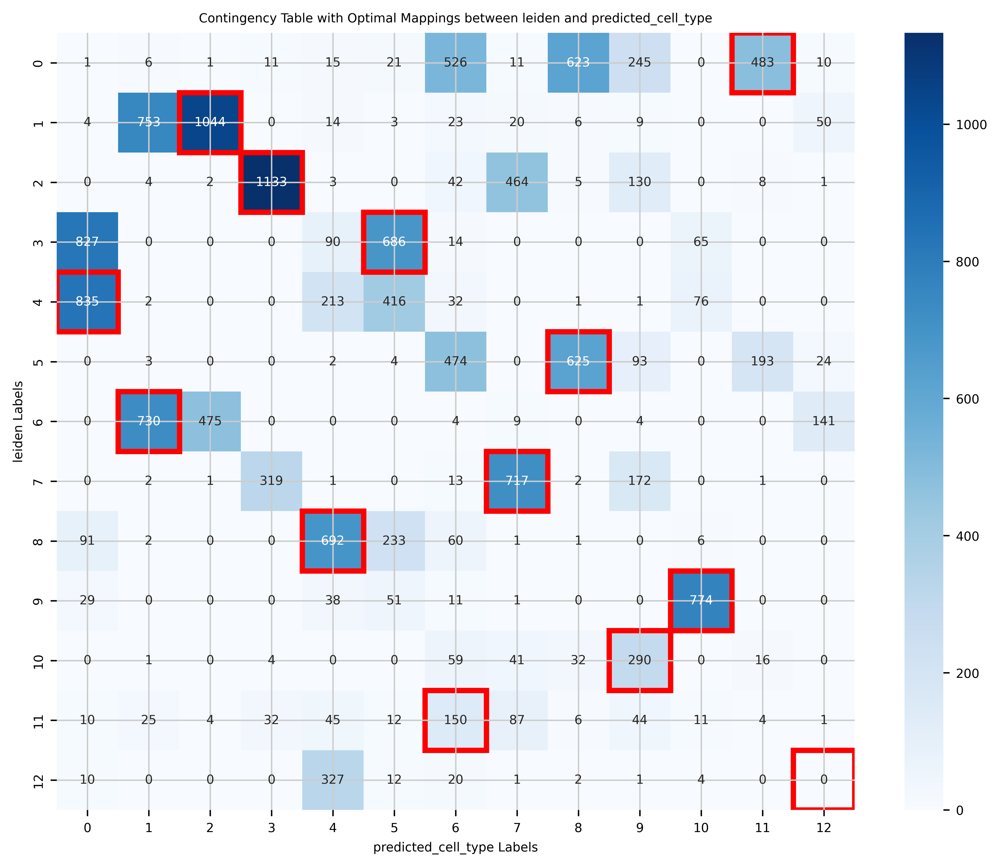

In [36]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [37]:
inferred_cell_types_ordered = [
    '11',
    '2',
    '3',
    '5',
    '0',
    '8',
    '1',
    '7',
    '4',
    '10',
    '9',
    '6',
    '12']

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


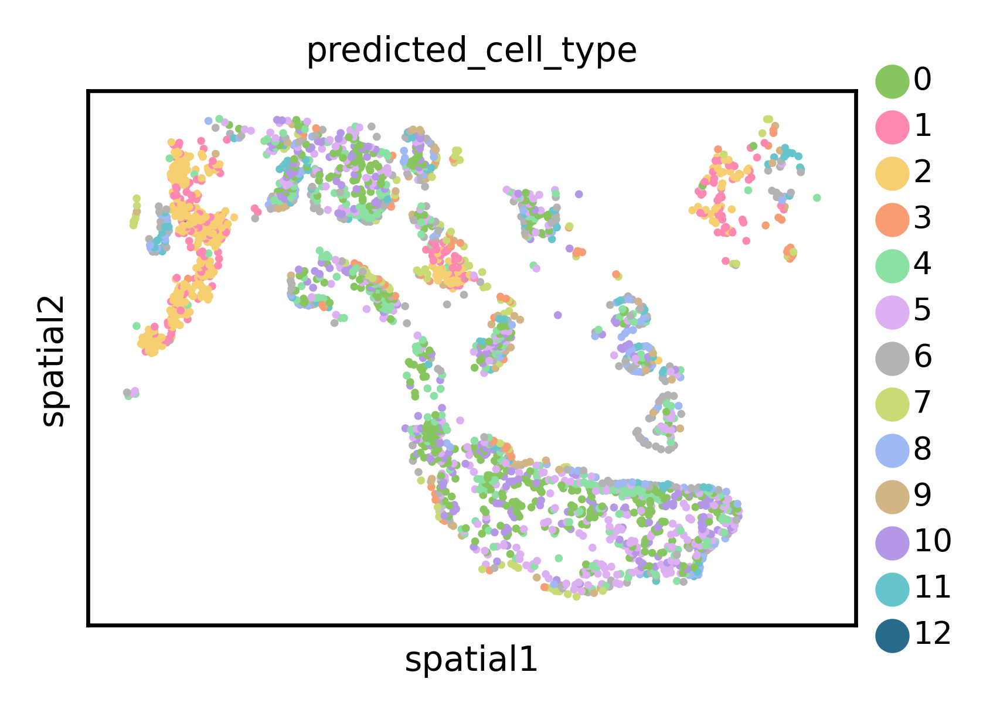

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


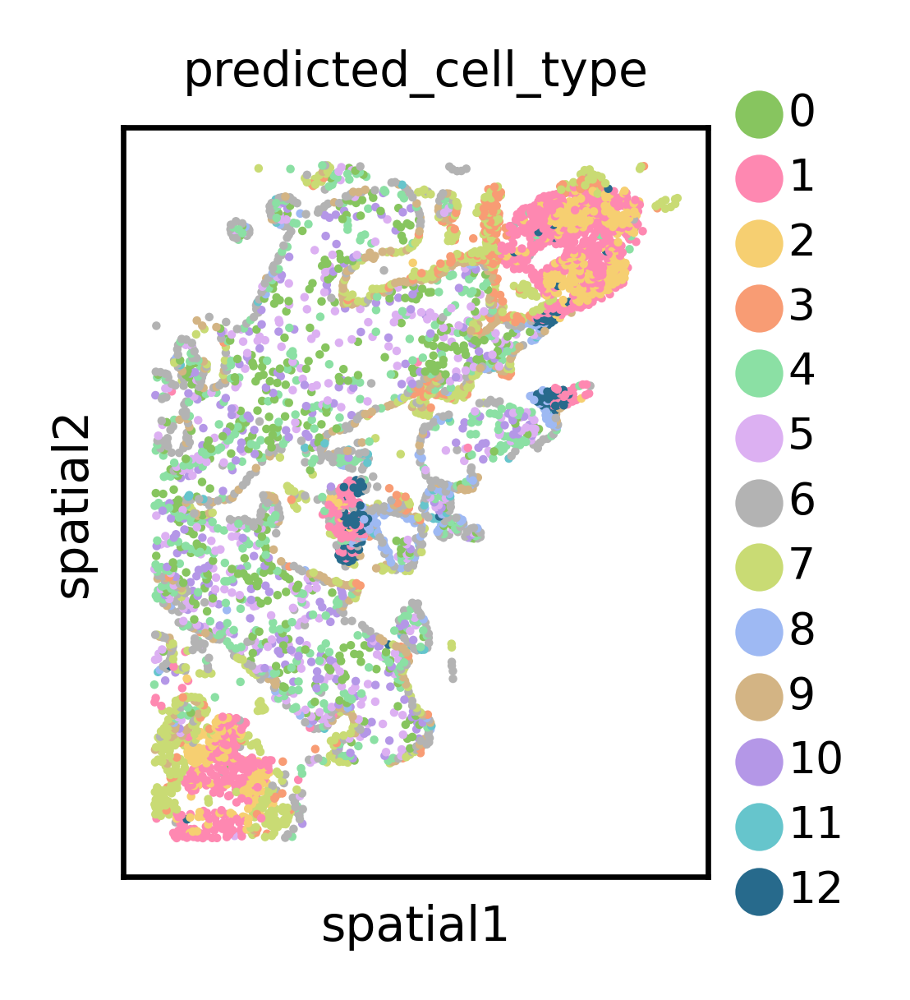

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


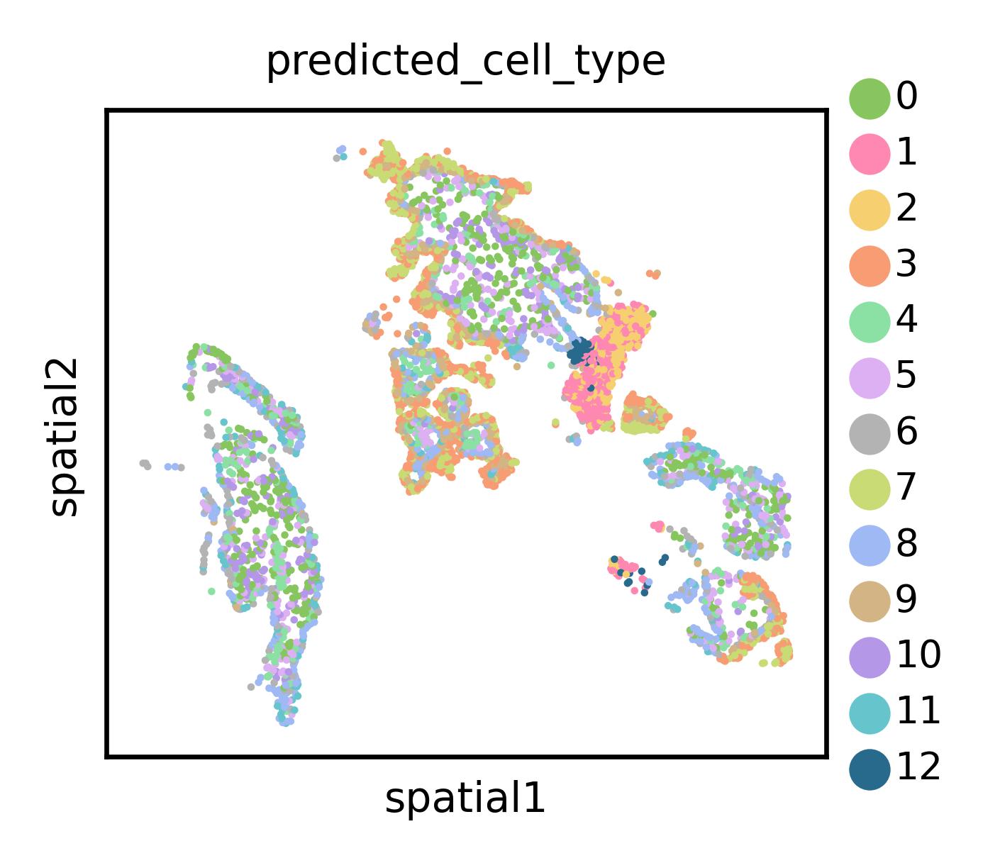

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


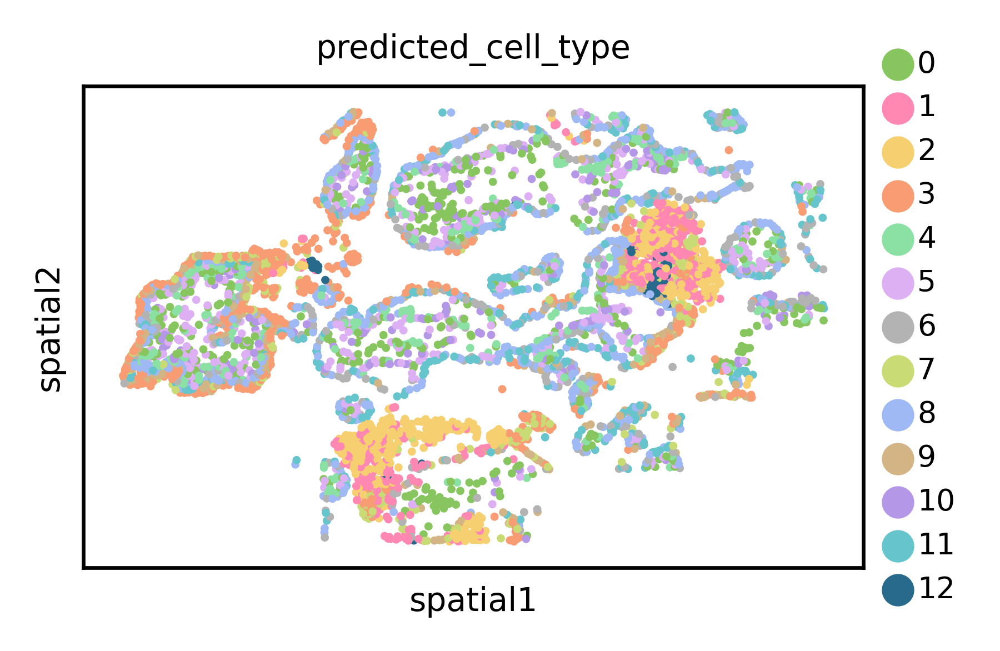

In [38]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [39]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.5592074055195307.
ARI scores: 0.3629016035834318.


#### 3.1.4 Quantitative Performance

In [40]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.5592074055195307, 0.5585209514824199, 0.5617909614576484, 0.5616445732852089, 0.5616499997947922, 0.5594988605151057, 0.5603879020056208, 0.5537542518146185, 0.557620132497858].
ARI scores: [0.3629016035834318, 0.3711867378641682, 0.36775011056681267, 0.3777680567855844, 0.37579107344492607, 0.374047015408784, 0.37225997773840297, 0.3644030321625553, 0.36418932946068483].


### 3.5 xhk1007-CV1-41b_1p (Xenium Human Renal Cell Carcinoma)

In [13]:
# Define dataset params
dataset_name = 'xhp1016-18b_1p'
batches = ['output-XETG00055__0073068__Hml4-PNC-0-FFPE-1-s4__20250814__132610', # batch3
           'output-XETG00055__0073075__Hml7-PNC-0-FFPE-1-s4__20250814__132610', # batch12
          ]
cell_type_key = 'Annotation_high'
batch_key = 'batch'
spot_sizes = [30] * len(batches)

#### 3.5.1 Load Data

In [14]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without cell type labels
            adata = adata[~adata.obs[cell_type_key].isna()]

            adata.obs[batch_key] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/tmp/ipykernel_1320700/2595844585.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/tmp/ipykernel_1320700/2595844585.py:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.

In [15]:
print(adata.obs[cell_type_key].value_counts())

Stromal (Fibroblast)         64627
Exocrine (Ductal)            23995
Endothelial                  23875
Exocrine (Acinar)            21260
Tip                          21213
Stromal (mural)              14609
Endocrine                    10385
Neural crest                 10296
Immune (Macrophage)           3750
Immune (T/NK/ILC)             2513
Immune (B)                    1773
Endocrine progenitor          1584
Erythrocyte/Megakaryocyte     1422
Stromal (Mesothelium)         1197
Immune (Granulocyte)           544
Immune (Mast cell)             166
Immune (Dendritic cell)         60
Epithelial Progenitor           47
Name: Annotation_high, dtype: int64


#### 3.5.2 Retrieve Embeddings

In [16]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Automatically converting gene symbols to ensembl ids...


INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:querying 5001-5047 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


After filtering, 4723 genes remain.


/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/CellPLM/utils/data.py:20: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at ../aten/src/ATen/SparseCsrTensorImpl.cpp:53.)
  return torch.sparse_csr_tensor(x.indptr, x.indices, x.data, (x.shape[0], x.shape[1])).to_sparse().float().coalesce()


In [17]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [19]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 3.5.3 Highlight Run (Matching Ground Truth Number of Niches)

In [38]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 16)
latent_leiden_resolution = 0.825

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [39]:
adata.obs[latent_cell_cluster_key].value_counts()

0     31371
1     30914
2     18070
3     17627
4     16782
5     16214
6     15061
7     11470
8     10202
9      9559
10     8586
11     7666
12     4424
13     2611
14     1634
15     1125
Name: predicted_cell_type, dtype: int64

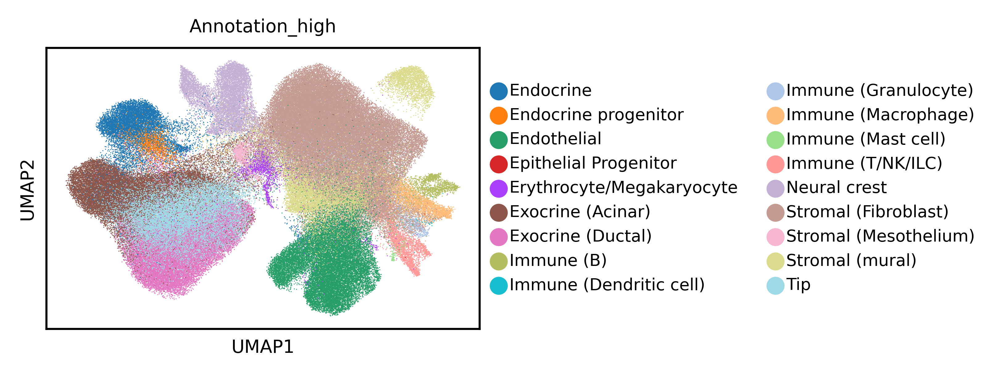

In [40]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [42]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered_cell_type.h5ad')

['8', '9', '2', '13', '4', '11', '14', '0', '1', '3', '6', '7', '10', '5', '12', '15']
0     31371
1     30899
2     18070
3     17627
4     16782
5     16213
6     15049
7     11468
8     10202
9      9540
10     8573
11     7666
12     4424
13     2611
14     1589
15     1125
Name: predicted_cell_type, dtype: int64
Optimal Mappings:
Endocrine -> 7 (Overlap: 9143)
Endocrine progenitor -> 12 (Overlap: 0)
Endothelial -> 4 (Overlap: 15284)
Erythrocyte/Megakaryocyte -> 10 (Overlap: 1171)
Exocrine (Acinar) -> 3 (Overlap: 13979)
Exocrine (Ductal) -> 1 (Overlap: 18534)
Immune (B) -> 14 (Overlap: 1538)
Immune (Granulocyte) -> 2 (Overlap: 7)
Immune (Macrophage) -> 9 (Overlap: 3320)
Immune (Mast cell) -> 13 (Overlap: 1)
Immune (T/NK/ILC) -> 5 (Overlap: 45)
Neural crest -> 8 (Overlap: 9224)
Stromal (Fibroblast) -> 0 (Overlap: 30454)
Stromal (Mesothelium) -> 15 (Overlap: 1085)
Stromal (mural) -> 11 (Overlap: 5024)
Tip -> 6 (Overlap: 6997)

Total Maximum Overlap: 115806


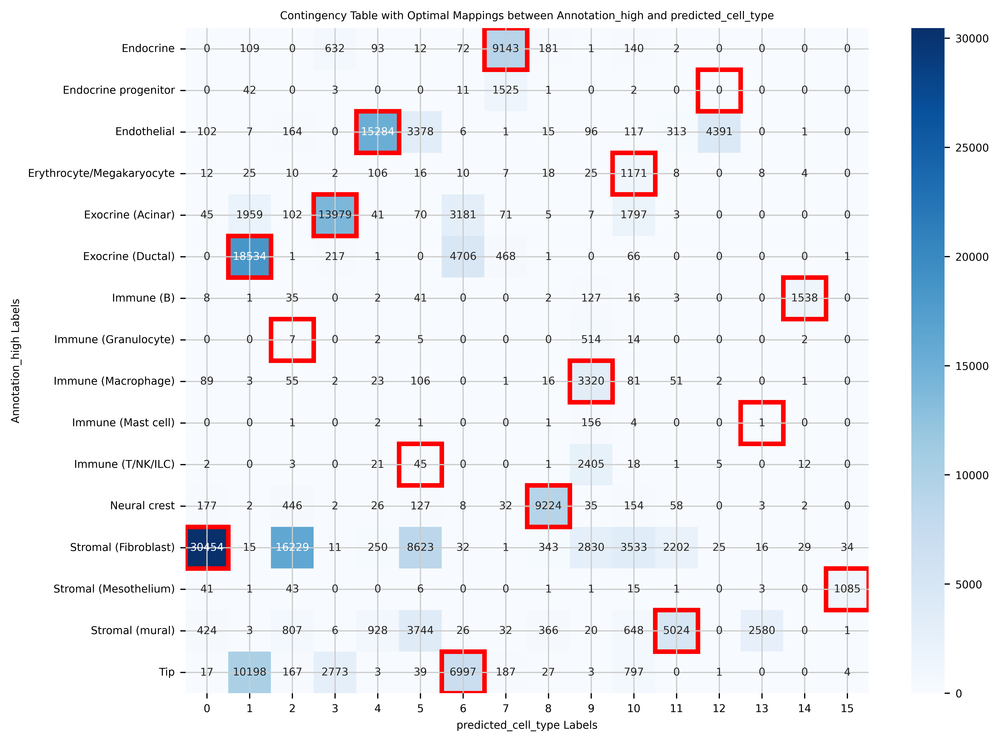

In [43]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [44]:
inferred_cell_types_ordered = [
    '7',
    '12',
    '4',
    '10',
    '3',
    '1',
    '14',
    '2',
    '9',
    '13',
    '5',
    '8',
    '0',
    '15',
    '11',
    '6',]

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


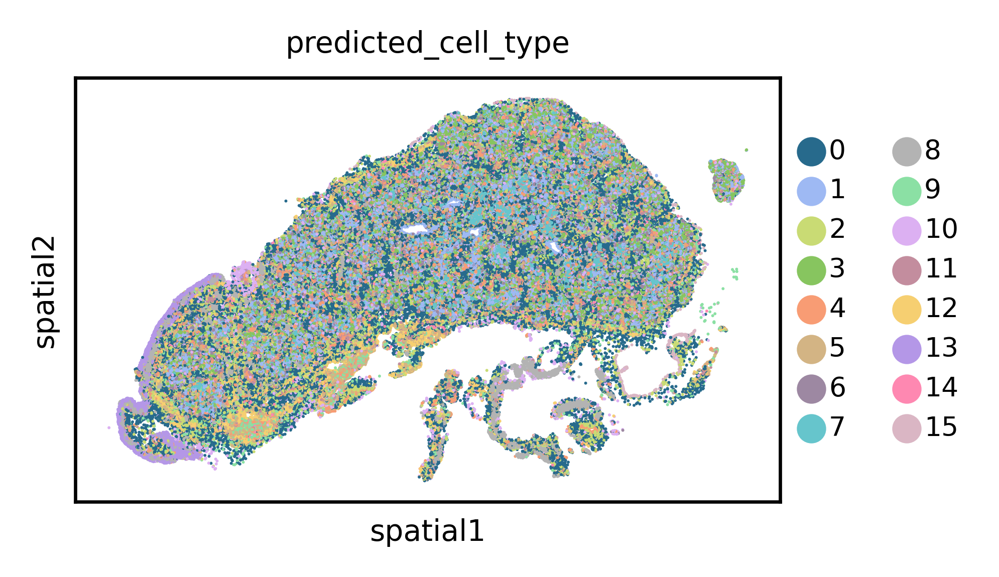

/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


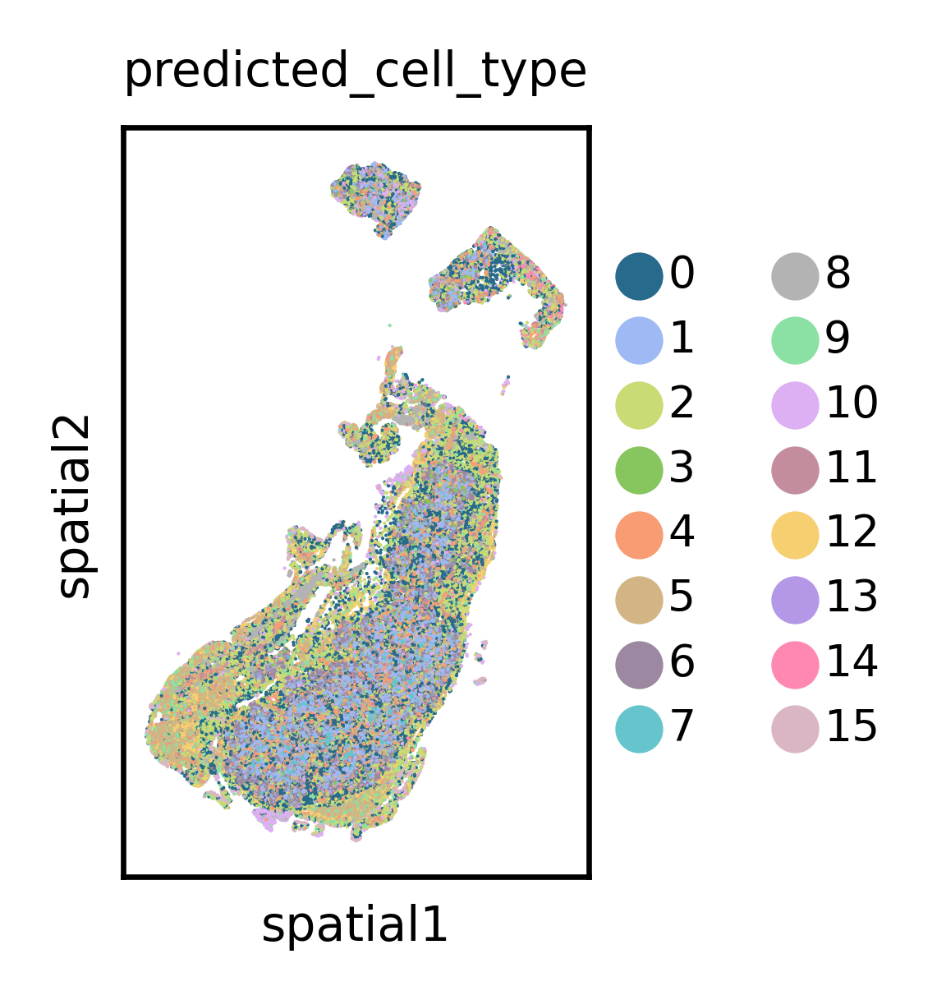

In [45]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_cellplm_cell_types.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cell_cluster_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [46]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.6071236971755581.
ARI scores: 0.41310216925944226.


#### 3.5.4 Quantitative Performance

In [47]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.6071236971755581, 0.6168518143955265, 0.6153861703513682, 0.6163156375817881, 0.617894055924082, 0.6180424759938085, 0.6094701430989697, 0.6153503294833759, 0.6107267542407951].
ARI scores: [0.41310216925944226, 0.4285049377094515, 0.41944344018556373, 0.4217292178803739, 0.4227055554096577, 0.4238853812055296, 0.4143091184266893, 0.41654900277421436, 0.41020142793517217].


### 3.6 shk2005-1b_1p (SlideSeqV2 Human Kidney)

In [121]:
# Define dataset params
dataset_name = 'shk2005-1b_1p'
cell_type_key = 'cell_type'
spot_size = 30

#### 3.6.1 Load Data

In [89]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Puck_200104_15_with_emb_NEMO_commongenes.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs[cell_type_key].isna()]

In [90]:
print(adata.obs[cell_type_key].value_counts())

endothelial cell                                             10239
kidney proximal convoluted tubule epithelial cell             4914
leukocyte                                                     1305
kidney collecting duct principal cell                         1150
kidney loop of Henle thick ascending limb epithelial cell      883
kidney distal convoluted tubule epithelial cell                621
kidney collecting duct intercalated cell                       581
kidney interstitial fibroblast                                 523
blood vessel smooth muscle cell                                371
podocyte                                                       255
kidney granular cell                                           233
macrophage                                                     162
macula densa epithelial cell                                    44
mesangial cell                                                  12
Name: cell_type, dtype: int64


#### 3.6.2 Retrieve Embeddings

In [91]:
# Retrieve embeddings for adata
embedding = pipeline.predict(adata,
                             device=DEVICE)
adata.obsm['emb'] = embedding.cpu().numpy()

INFO:biothings.client:querying 1-1000 ...


Automatically converting gene symbols to ensembl ids...


INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-3659 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.
/software/cellgen/team361/sb75/envs/cellplm/lib/python3.9/site-packages/CellPLM/utils/data.py:81: UserWarning: Batch labels not found in AnnData.obs. All cells are considered from the same sample by default.
  warnings.warn(


After filtering, 3453 genes remain.


/tmp/ipykernel_1320700/1236688796.py:4: ImplicitModificationWarning: Setting element `.obsm['emb']` of view, initializing view as actual.
  adata.obsm['emb'] = embedding.cpu().numpy()


In [92]:
# Compute neighbors and UMAP 
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb')

In [93]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded.h5ad')

#### 3.6.3 Highlight Run (Matching Ground Truth Number of Niches)

In [108]:
# Compute Leiden clustering (matching the number of clusters with the ground truth with > 100 cells -> 12)
latent_leiden_resolution = 1.01

sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cell_cluster_key,
             resolution=latent_leiden_resolution)

In [109]:
adata.obs[latent_cell_cluster_key].value_counts()

0     3017
1     2909
2     2834
3     2264
4     2195
5     1944
6     1628
7     1431
8     1372
9     1082
10     377
11     240
Name: predicted_cell_type, dtype: int64

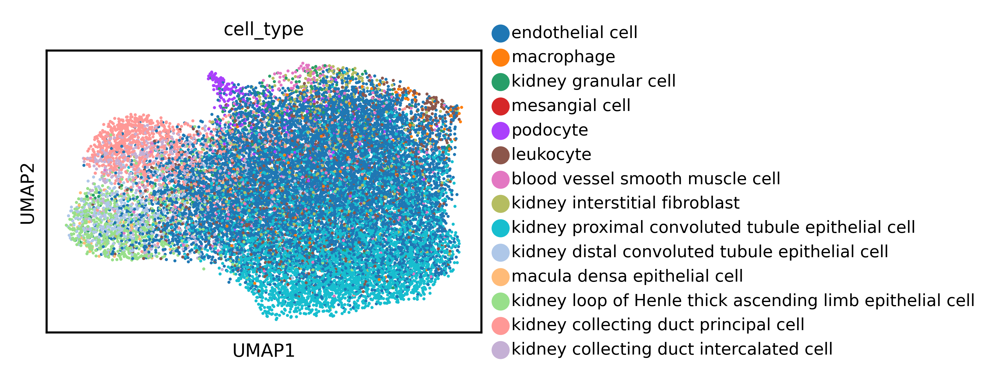

In [110]:
# Visualize UMAP
sc.pl.umap(adata, color=cell_type_key)

In [150]:
# Save updated AnnData
try:
    del(adata.uns['spatial'])
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/CellPLM/{dataset_name}_embedded_clustered_cell_type.h5ad')

['7', '9', '5', '1', '10', '3', '4', '8', '6', '2', '0', '11']
0     3011
1     2906
2     2834
3     2263
4     2194
5     1943
6     1591
7     1426
8     1372
9     1081
10     377
11     239
Name: predicted_cell_type, dtype: int64
Optimal Mappings:
endothelial cell -> 1 (Overlap: 1638)
macrophage -> 9 (Overlap: 5)
kidney granular cell -> 10 (Overlap: 3)
podocyte -> 11 (Overlap: 135)
leukocyte -> 0 (Overlap: 241)
blood vessel smooth muscle cell -> 7 (Overlap: 86)
kidney interstitial fibroblast -> 3 (Overlap: 117)
kidney proximal convoluted tubule epithelial cell -> 2 (Overlap: 1863)
kidney distal convoluted tubule epithelial cell -> 4 (Overlap: 91)
kidney loop of Henle thick ascending limb epithelial cell -> 6 (Overlap: 621)
kidney collecting duct principal cell -> 8 (Overlap: 760)
kidney collecting duct intercalated cell -> 5 (Overlap: 28)

Total Maximum Overlap: 5588


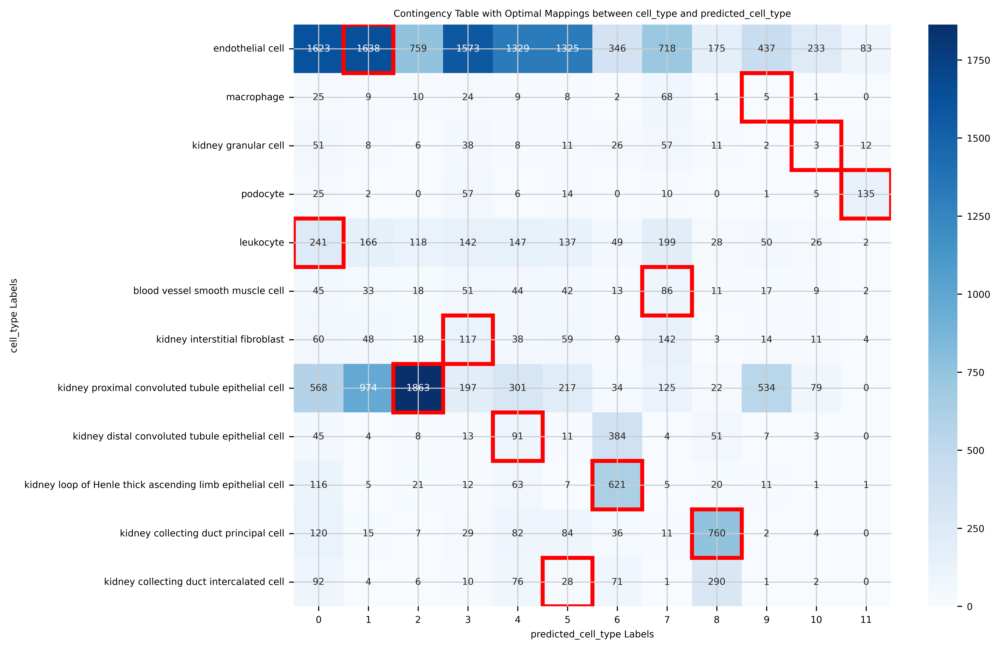

In [145]:
cell_type_counts = (adata.obs[cell_type_key].value_counts() < 100)
invalid_cell_types = cell_type_counts[cell_type_counts].index.tolist()

latent_cluster_counts = (adata.obs[latent_cell_cluster_key].value_counts() < 100)
invalid_clusters = latent_cluster_counts[latent_cluster_counts].index.tolist()

mask = (~adata.obs[cell_type_key].isin(invalid_cell_types)) & (~adata.obs[latent_cell_cluster_key].isin(invalid_clusters))
filtered_df = adata.obs[mask]

print(filtered_df[latent_cell_cluster_key].unique().tolist())
print(filtered_df[latent_cell_cluster_key].value_counts())

max_overlap_plot(filtered_df, cell_type_key, latent_cell_cluster_key)

In [146]:
inferred_cell_types_ordered = [
    '1',
    '9',
    '10',
    '11',
    '0',
    '7',
    '3',
    '2',
    '4',
    '6',
    '8',
    '5',]

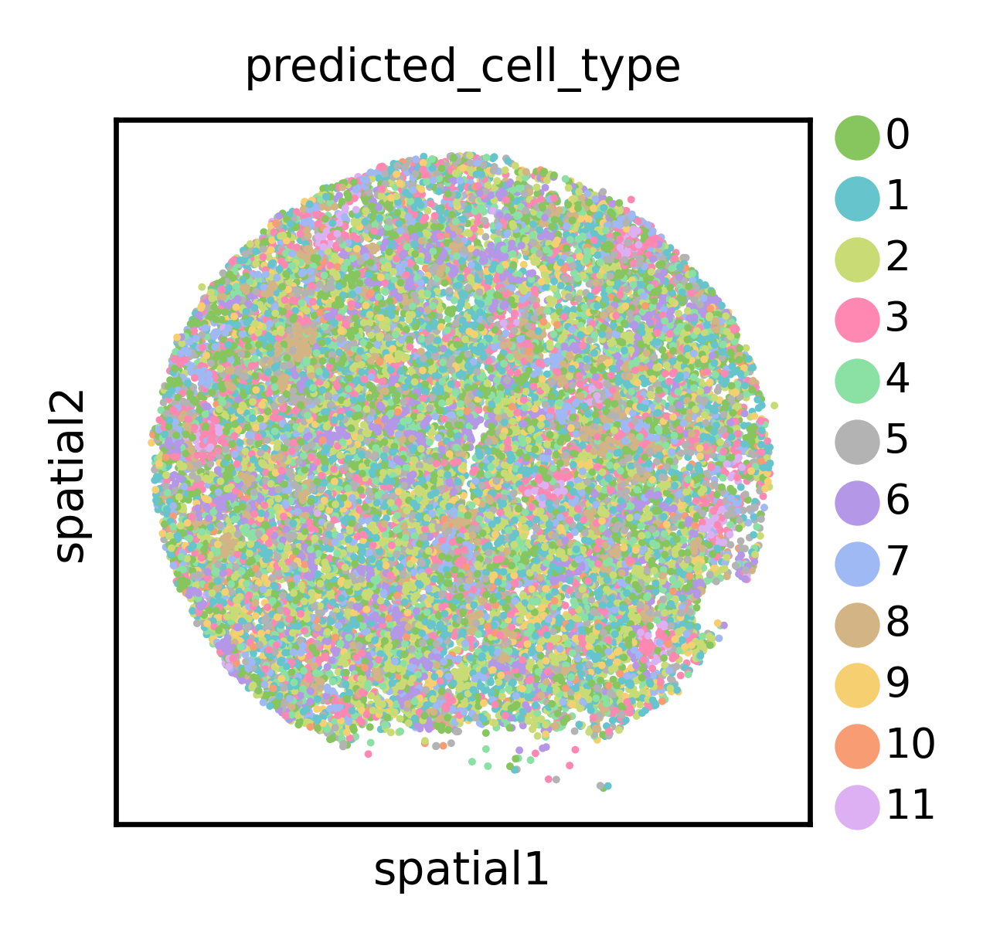

In [151]:
# Plot cellplm cell types
label2celltype = {}
current_index = 0  # To keep track of the new indices

for cell_type in inferred_cell_types_ordered:
    if not isinstance(cell_type, str):
        if math.isnan(cell_type):
            continue # skip NaN values
    label2celltype[str(current_index)] = cell_type
    current_index += 1

pred_palette = {
    label2celltype.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_cellplm_cell_types.svg'
sc.pl.spatial(adata,
              color=latent_cell_cluster_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

In [152]:
# Compute metrics
labels = adata.obs[cell_type_key]
labels_pred = adata.obs[latent_cell_cluster_key]
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari_score = adjusted_rand_score(labels, labels_pred)

print(f"NMI scores: {nmi_score}.")
print(f"ARI scores: {ari_score}.")

NMI scores: 0.18457933241315466.
ARI scores: 0.07340661353087669.


#### 3.6.4 Quantitative Performance

In [153]:
# Compute metrics over different resolutions
nmi_scores = []
ari_scores = []
n_cell_types_list = []

nmi_scores.append(nmi_score)
ari_scores.append(ari_score)
n_cell_types_list.append(adata.obs[latent_cell_cluster_key].nunique())

latent_leiden_resolution_list = [latent_leiden_resolution,
                                 latent_leiden_resolution-0.04,
                                 latent_leiden_resolution-0.03,
                                 latent_leiden_resolution-0.02,
                                 latent_leiden_resolution-0.01,
                                 latent_leiden_resolution+0.01,
                                 latent_leiden_resolution+0.02,
                                 latent_leiden_resolution+0.03,
                                 latent_leiden_resolution+0.04]

for i, latent_leiden_resolution in enumerate(latent_leiden_resolution_list[1:]):

    sc.tl.leiden(adata,
                 neighbors_key='emb',
                 key_added=latent_neighborhood_cluster_key,
                 resolution=latent_leiden_resolution)

    n_cell_types_list.append(adata.obs[latent_neighborhood_cluster_key].nunique())
    
    labels = adata.obs[cell_type_key]
    labels_pred = adata.obs[latent_neighborhood_cluster_key]
    labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])
    
    nmi_score = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
    ari_score = adjusted_rand_score(labels, labels_pred)

    nmi_scores.append(nmi_score)
    ari_scores.append(ari_score)

    # Store on disk
    metrics_df = pd.DataFrame({
        'leiden_resolution': latent_leiden_resolution_list[:i+2],
        'n_cell_types': n_cell_types_list,
        'NMI': nmi_scores,
        'ARI': ari_scores
    })
    metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_cellplm_metric_scores_cell_type.csv', index=False)

print(f"NMI scores: {nmi_scores}.")
print(f"ARI scores: {ari_scores}.")

NMI scores: [0.18457933241315466, 0.19056771637616413, 0.18743659774833138, 0.1875406599542966, 0.18473763109258623, 0.1933931443284917, 0.1885619820360634, 0.18545487302990374, 0.18457933241315466].
ARI scores: [0.07340661353087669, 0.09054266906017534, 0.08355654722106823, 0.08370736879863637, 0.07218260919405503, 0.09072905071843781, 0.07746069128476704, 0.07593503329065251, 0.07340661353087669].
